# Recipe 10 — Crete Flood from Satellite Imagery

:::{admonition} Recipe Overview
:class: important

| | |
|---|---|
| **Goal** | Turn a Copernicus EMS rapid-mapping activation in Montandon into an interactive picture of a flood: before/after satellite imagery, flood extent and depth, the land and buildings under the water |
| **Data Sources** | Montandon STAC (`cems-hazards`, `cems-response`), CEMS satellite pictures (COG) and flood layers (GeoJSON), Sentinel-2 L2A, ESA WorldCover 2021, Overture Maps buildings {cite}`cems,sentinel2,worldcover,overture` |
| **Key Libraries** | `pystac-client`, `rasterio`, `geopandas`, `lonboard`, `manywidgets` {cite}`pystac_client,lonboard` |
| **Difficulty** | Advanced |
| **Time** | ~10 minutes to run; the results read without running anything |
:::

## What this notebook shows

In early October 2026 a flash flood hit Crete, Greece. The Copernicus Emergency Management Service (CEMS) was activated as **EMSR933**, split the area into **8 mapping zones**, and delivered satellite pictures and flood maps. Montandon holds all of it as STAC items: one **hazard** item per zone and the **response** items that link to the pictures and the flood layers.

The results (Part C) answer four questions, one after the other:

1. **Where did it flood?** A before/after swipe of satellite imagery for the whole activation.
2. **How deep?** CEMS's modelled water-depth classes.
3. **What land was under the water?** ESA WorldCover land types inside the flood.
4. **Which buildings?** Overture Maps building footprints inside the flood.

Part B holds all the code. It is collapsed on the website; open it to see how each number is made.

## Data sources and definitions

| Source | What it gives us | How it is read |
|---|---|---|
| **Montandon** `cems-hazards`, `cems-response` | the 8 zones, the delivered maps and links to their files | STAC API search |
| **CEMS satellite pictures** (COG) | post-event optical imagery, about 1-1.6 m per pixel | map tiles cut on the fly by [titiler](https://titiler.xyz); never downloaded |
| **CEMS flood layers** (GeoJSON) | flood seen on the pictures, modelled flood area, modelled depth classes | downloaded once (under 0.3 MB each) |
| **Sentinel-2 L2A** | the "before" imagery: per tile, the September 2026 scene with the most clear ground (under 15 % cloud) | Earth Search STAC, tiled by titiler |
| **ESA WorldCover 2021** | land type at 10 m (cropland, grassland, built-up, ...) | read only inside the flood polygons |
| **Overture Maps** buildings | building footprints | read only around the flood areas |

- **Seen flood** (`observedEventA`): flood traces CEMS mapped from the post-event pictures, by photo-interpretation or semi-automatic extraction.
- **Modelled flood area** (`modelledEventA`, `floodDepthA`): CEMS's modelled flood area; where published, it is split into **depth classes** (below 0.5 m up to over 4 m). Depths are modelled, not measured.
- **Maximum flood extent** (`maximumFloodExtentA`, zone 3 only): the largest area the water reached during the monitoring period.
- Areas are measured on the ground in a local metric projection, with overlaps counted once.

:::{note}
This recipe reads the **production** Montandon API (`montandon-eoapi.ifrc.org`), where EMSR933 is published; the other recipes use staging.
:::

## Environment Setup

::::{tab-set}
:::{tab-item} Binder
All dependencies are pre-installed. Click **Launch Binder** at the top of the page — no setup needed.
:::
:::{tab-item} Google Colab
Run this in the first code cell before anything else:
```python
!pip install -q pystac-client rasterio geopandas overturemaps "lonboard==0.17.0" "manywidgets[lonboard,numpy]==0.3.0"
import os; from getpass import getpass
if 'MONTANDON_API_TOKEN' not in os.environ:
    os.environ['MONTANDON_API_TOKEN'] = getpass('API token: ')
```
:::
:::{tab-item} Local
```bash
pip install -e .          # from repo root
export MONTANDON_API_TOKEN='your_token_here'
jupyter lab
```
See [Getting Started](../getting-started) for token instructions.
:::
::::

---
# Part B — Data preparation

Everything is computed here; Part C only displays the results.

### B1 · Settings and imports

In [1]:
from __future__ import annotations

import math
import os
import re
from contextlib import contextmanager
from dataclasses import dataclass, field
from getpass import getpass
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
import requests
import shapely
from IPython.display import display
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from shapely.geometry import box, shape

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 90)

# ---- settings you can change ------------------------------------------------
ACTIVATION = "EMSR933"        # the CEMS activation (the Crete flood)
ZONES = None                  # None = every zone that has flood layers; or a list such as [1, 7]
INCLUDE_NOT_ANALYSED = False  # "notAnalysedA" layers can be big (13 MB for zone 1); not needed here
# -----------------------------------------------------------------------------

API_URL = "https://montandon-eoapi.ifrc.org/stac"     # NOTE: production API; EMSR933 is published there
HERE = Path.cwd()
CACHE = HERE / "data" / "cache"

api_token = os.environ.get("MONTANDON_API_TOKEN") or getpass("Montandon API token (from https://goadmin.ifrc.org/): ")

# GDAL settings that make remote COG reads efficient (range requests, no directory listing)
GDAL_OPTS = dict(
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.tiff",
    GDAL_HTTP_MAX_RETRY="4",
    GDAL_HTTP_RETRY_DELAY="1",
    GDAL_HTTP_TIMEOUT="60",
)
print("rasterio", rasterio.__version__, "| GDAL", rasterio.__gdal_version__, "| geopandas", gpd.__version__)

rasterio 1.5.2 | GDAL 3.12.2 | geopandas 1.2.0


### B2 · Load the Montandon items

Two collections matter: `cems-hazards` (one item per zone: the hazard polygon) and `cems-response` (the maps CEMS delivered, with links to the pictures and the flood layers).

In [2]:
def search_api(token: str, collection: str) -> list[dict]:
    """POST /search, following the `next` links (their body replaces the request body)."""
    url, headers = f"{API_URL}/search", {"Authorization": f"Bearer {token}"}
    body = {"collections": [collection], "limit": 500}
    items: list[dict] = []
    while True:
        r = requests.post(url, json=body, headers=headers, timeout=120)
        r.raise_for_status()
        page = r.json()
        items += page["features"]
        nxt = next((l for l in page.get("links", []) if l["rel"] == "next"), None)
        if not nxt or not page["features"]:
            return items
        body = {**body, **nxt["body"]} if nxt.get("merge") else nxt["body"]


all_items = search_api(api_token, "cems-response")
items = [i for i in all_items if i["id"].startswith(f"cems-response-{ACTIVATION}-")]
all_hazards = search_api(api_token, "cems-hazards")
hazards = [h for h in all_hazards if h["id"].startswith(f"cems-hazard-{ACTIVATION}-")]
print(f"{len(items)} response items and {len(hazards)} hazard items for {ACTIVATION}, loaded from the live Montandon API")

50 response items and 8 hazard items for EMSR933, loaded from the live Montandon API


### B3 · Zones and their flood layers

For each zone we take its newest published delineation item, and from it the picture link and the flood-layer links. A zone is analysed only if it has flood layers. *imagery listed* shows acquisitions Montandon knows about as metadata; only a picture **file** can be shown.

In [3]:
def asset_kind(asset: dict) -> str | None:
    t = asset.get("type", "")
    if "tiff" in t:
        return "cog"          # satellite picture
    if t == "application/geo+json":
        return "geojson"      # flood layer
    return None


def zone_of(item_id: str) -> int | None:
    m = re.search(r"aoi(\d+)", item_id)
    return int(m.group(1)) if m else None


def class_start(v) -> float:
    """Sort key for depth classes: 'Below 0.50' < '1.00 to 2.00' < 'Above 4.00'."""
    words = str(v).split()
    first = words[0].lower()
    if first == "below":
        return 0.0
    if first == "above":
        return float(words[1]) + 0.001
    return float(words[0])


def sort_classes(values) -> list:
    try:
        return sorted(values, key=class_start)
    except (ValueError, IndexError):
        return sorted(values, key=str)


def area_km2(g) -> float:
    """Ground area in km2 (overlaps counted once), measured in a local metric projection."""
    g = g[g.geometry.notna() & ~g.geometry.is_empty]
    return 0.0 if g.empty else float(g.to_crs(g.estimate_utm_crs()).geometry.union_all().area / 1e6)


def fetch(href: str) -> Path:
    """Download a small file once; later runs reuse data/cache."""
    if not href.startswith("http"):
        return Path(href)
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / href.rsplit("/", 1)[-1]
    if not path.exists():
        r = requests.get(href, timeout=120)
        r.raise_for_status()
        path.write_bytes(r.content)
    return path


def drawn_layers(layers: dict) -> dict:
    """Skip modelledEventA when floodDepthA covers exactly the same ground (the depth layer is that area in classes)."""
    m, d = layers.get("modelledEventA"), layers.get("floodDepthA")
    if m is not None and d is not None and not m.empty and not d.empty:
        mu, du = m.to_crs(4326).geometry.union_all(), d.to_crs(4326).geometry.union_all()
        if mu.symmetric_difference(du).area < 1e-3 * max(mu.area, 1e-12):
            return {k: g for k, g in layers.items() if k != "modelledEventA"}
    return layers


@dataclass
class Zone:
    n: int
    name: str
    hazard: gpd.GeoDataFrame | None = None       # Montandon hazard polygon (lon/lat)
    max_extent_km2: float | None = None          # "Maximum extent" stored on the Montandon hazard item
    delin: dict | None = None                    # the delineation item that carries the flood files
    cog_href: str | None = None                  # satellite picture (COG) of that item
    picture: str = "no picture"                  # which satellite, and when
    imagery: list = field(default_factory=list)  # acquisitions listed in Montandon (metadata, may have no file)
    layers: dict = field(default_factory=dict)   # flood layers (GeoDataFrames)
    draw: dict = field(default_factory=dict)     # the layers drawn on the panels
    cog: dict = field(default_factory=dict)      # facts about the COG (filled in section 4)
    spots: list = field(default_factory=list)    # close-up windows (filled in section 7), in the picture's CRS
    crs: object = None
    why_not: str = ""                            # reason a zone is skipped


# which satellite took each picture? look it up on the matching image (eo-dat) items
sensor_by_href = {
    a["href"]: (it["properties"].get("platform"), it["properties"]["datetime"])
    for it in items if it["properties"]["monty:response_detail"]["type"] == "eo-dat"
    for a in it["assets"].values() if asset_kind(a) == "cog"
}

zones: dict[int, Zone] = {}
for h in hazards:
    n = zone_of(h["id"])
    if n is None:
        continue
    title = h["properties"].get("title", f"Zone {n}")
    z = zones.setdefault(n, Zone(n, name=re.split(r"\s+[\u2014-]\s+", title)[0]))
    g = gpd.GeoDataFrame({"id": [h["id"]]}, geometry=[shape(h["geometry"])], crs=4326)
    z.hazard = g if z.hazard is None else pd.concat([z.hazard, g], ignore_index=True)
    sev = (h["properties"].get("monty:hazard_detail") or {}).get("severity_value")
    z.max_extent_km2 = z.max_extent_km2 if z.max_extent_km2 is not None else sev
for it in items:
    n = zone_of(it["id"])
    if n is None:
        continue
    z = zones.setdefault(n, Zone(n, name=f"Zone {n}"))
    if it["properties"]["monty:response_detail"]["type"] == "eo-dat":
        z.imagery.append(f"{it['properties'].get('platform') or 'satellite'} {it['properties']['datetime'][:16].replace('T', ' ')}")

for n, z in sorted(zones.items()):
    cands = [
        it for it in items
        if zone_of(it["id"]) == n and it["properties"]["monty:response_detail"]["type"] == "eo-del"
        and any(asset_kind(a) == "geojson" for a in it["assets"].values())
    ]
    if not cands:
        z.why_not = "no flood layers (GeoJSON) published"
        continue
    cands.sort(key=lambda it: it["properties"]["monty:response_detail"].get("monitoring_number") or 0, reverse=True)
    z.delin = cands[0]
    cog = next(((k, a) for k, a in z.delin["assets"].items() if asset_kind(a) == "cog"), None)
    if cog:
        z.cog_href = cog[1]["href"]
        platform, taken = sensor_by_href.get(z.cog_href, (None, None))      # no matching image item -> date unknown
        z.picture = f"{platform or 'satellite'} {taken[:16].replace('T', ' ')} UTC" if taken else f"{platform or 'satellite'}, date unknown"
    for key, asset in z.delin["assets"].items():
        if asset_kind(asset) != "geojson":
            continue
        name = key.rsplit("_", 1)[-1]                      # e.g. observedEventA
        if name == "notAnalysedA" and not INCLUDE_NOT_ANALYSED:
            continue
        g = gpd.read_file(fetch(asset["href"]))
        z.layers[name] = g.set_crs(4326) if g.crs is None else g
    z.draw = drawn_layers(z.layers)

analysed = [z for n, z in sorted(zones.items()) if z.layers and (ZONES is None or n in ZONES)]

display(pd.DataFrame([
    dict(zone=z.n, name=z.name,
         picture_file=z.picture if z.cog_href else "none",
         imagery_listed="; ".join(z.imagery) or "-",
         flood_layers=", ".join(f"{k} ({len(g)})" for k, g in z.layers.items()) or "-",
         analysed=("yes" + ("" if z.cog_href else " (basemap, no picture file)")) if z in analysed
                  else "no - " + (z.why_not or "not selected in ZONES"))
    for n, z in sorted(zones.items())
]).set_index("zone"))

,name,picture_file,imagery_listed,flood_layers,analysed
zone,,,,,
1,Kastelli,Legion 2026-10-06 10:47 UTC,Legion 2026-10-06 10:47; Legion 2026-10-06 10:46; Sentinel-1 2026-10-04 16:22,"floodDepthA (87), modelledEventA (56), observedEventA (88)",yes
2,Irakleio,none,Legion 2026-10-06 10:47; Legion 2026-10-06 10:46; Sentinel-1 2026-10-04 16:22,-,no - no flood layers (GeoJSON) published
3,Tzermiado,GeoEye-1 2026-10-08 09:02 UTC,Legion 2026-10-09 09:32; WorldView-2 2026-10-09 09:08; GeoEye-1 2026-10-08 09:02; Worl...,"floodDepthA (57), modelledEventA (17), observedEventA (618), maximumFloodExtentA (12)",yes
4,Agios Ioannis,WorldView-3 2026-10-06 10:46 UTC,WorldView-3 2026-10-06 10:46; WorldView-3 2026-10-06 08:47; ICEYE 2026-10-04 23:16; IC...,observedEventA (30),yes
5,Anogeia,none,WorldView-3 2026-10-08 11:02; GeoEye-1 2026-10-08 09:48; Sentinel-1 2026-10-04 16:22,-,no - no flood layers (GeoJSON) published
6,Agios Nikolaos,Legion 2026-10-08 08:55 UTC,Legion 2026-10-08 08:55; Legion 2026-10-08 08:54; Sentinel-1 2026-10-05 04:23; Sentine...,observedEventA (11),yes
7,Omalos,Legion 2026-10-06 10:45 UTC,Legion 2026-10-06 10:45; Legion 2026-10-06 09:33; Sentinel-1 2026-10-04 16:21,"floodDepthA (80), modelledEventA (34), observedEventA (63)",yes
8,Monastiraki,none,WorldView-3 2026-10-06 10:46; WorldView-3 2026-10-06 08:47; ICEYE 2026-10-04 23:16; IC...,-,no - no flood layers (GeoJSON) published


### B4 · Satellite pictures

Each picture is a Cloud Optimized GeoTIFF: a GeoTIFF stored in tiles with smaller overview copies inside, so a program can fetch only the part it needs. That is how the 100-570 MB files are shown without downloading them.

In [4]:
def vsi(href: str) -> str:
    return f"/vsicurl/{href}" if href.startswith("http") else href


@contextmanager
def open_cog(href: str):
    with rasterio.Env(**GDAL_OPTS), rasterio.open(vsi(href)) as src:
        yield src


def remote_size_mb(href: str) -> float | None:
    try:
        if href.startswith("http"):
            return int(requests.head(href, timeout=30, allow_redirects=True).headers["Content-Length"]) / 1e6
        return os.path.getsize(href) / 1e6
    except Exception:
        return None


facts = []
for z in analysed:
    if not z.cog_href:
        continue
    with open_cog(z.cog_href) as src:
        footprint = gpd.GeoSeries([box(*transform_bounds(src.crs, "EPSG:4326", *src.bounds))], crs=4326)
        ground_km2 = area_km2(footprint)
        size = remote_size_mb(z.cog_href)
        z.cog = dict(ground_px_m=float(np.sqrt(ground_km2 * 1e6 / (src.width * src.height))))
        row = {
            "zone": z.n, "picture": z.picture,
            "file size (MB)": round(size, 1) if size else "n/a",
            "pixels (w x h)": f"{src.width} x {src.height}", "bands": src.count,
            "pixel type": ", ".join(sorted(set(src.dtypes))), "CRS": src.crs.to_string(),
            "pixel on the ground (m)": round(z.cog["ground_px_m"], 2),
            "tile size": str(src.block_shapes[0]), "overviews": str(src.overviews(1)),
            "picture area (km2)": round(ground_km2, 1),
        }
        if z.hazard is not None:
            hz = gpd.GeoSeries([z.hazard.geometry.union_all()], crs=4326)
            inside = area_km2(footprint.intersection(hz))
            row["hazard polygon (km2)"] = round(area_km2(hz), 1)
            row["share of the picture inside the hazard polygon"] = f"{inside / ground_km2:.0%}"
    facts.append(row)

if facts:
    display(pd.DataFrame(facts).set_index("zone").T)
else:
    print("None of the analysed zones has a picture.")

zone,1,3,4,6,7
picture,Legion 2026-10-06 10:47 UTC,GeoEye-1 2026-10-08 09:02 UTC,WorldView-3 2026-10-06 10:46 UTC,Legion 2026-10-08 08:55 UTC,Legion 2026-10-06 10:45 UTC
file size (MB),570.6,201.7,99.6,138.7,351.8
pixels (w x h),16610 x 16662,9624 x 6989,9066 x 5480,8210 x 5835,14517 x 12673
bands,3,3,3,3,3
pixel type,uint8,uint8,uint8,uint8,uint8
CRS,EPSG:3857,EPSG:3857,EPSG:3857,EPSG:3857,EPSG:3857
pixel on the ground (m),0.98,1.63,1.31,1.63,1.31
tile size,"(512, 512)","(512, 512)","(512, 512)","(512, 512)","(512, 512)"
overviews,"[2, 4, 8, 16, 32, 64]","[2, 4, 8, 16, 32]","[2, 4, 8, 16, 32]","[2, 4, 8, 16, 32]","[2, 4, 8, 16, 32]"
picture area (km2),265.5,179.3,85.0,127.5,313.4


### B5 · Flood extent and depth per zone

In [5]:
# ---- one table per flood layer, all zones together, in lon/lat ------------------------------------
import shapely

FLOOD_LAYERS = ["observedEventA", "modelledEventA", "floodDepthA", "maximumFloodExtentA"]


def layer_frame(name: str) -> gpd.GeoDataFrame:
    parts = [
        z.layers[name].to_crs(4326).assign(zone=z.n, zone_name=z.name)
        for z in analysed if name in z.layers and not z.layers[name].empty
    ]
    if not parts:
        return gpd.GeoDataFrame({"zone": [], "zone_name": []}, geometry=[], crs=4326)
    return gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=4326)


flood = {name: layer_frame(name) for name in FLOOD_LAYERS}

# depth classes come as text ("Below 0.50", "0.50 to 1.00", ..., "Above 4.00")
DEPTH_COL = "value"
DEPTH_CLASSES = sort_classes(flood["floodDepthA"][DEPTH_COL].dropna().unique()) if not flood["floodDepthA"].empty else []


def depth_floor(label: str) -> float:
    """Lower bound in metres of a depth class: 'Below 0.50' -> 0, '2.00 to 4.00' -> 2, 'Above 4.00' -> 4."""
    words = str(label).split()
    return 0.0 if words[0].lower() == "below" else float(words[-1] if words[0].lower() == "above" else words[0])


def zone_union(name: str, n: int):
    """Union of one flood layer in one zone (None when the zone has no such layer)."""
    g = flood[name]
    g = g[g["zone"] == n]
    return None if g.empty else g.geometry.union_all()


# "seen" = flood traced on the satellite pictures; "modelled" = CEMS's modelled flood area (with depth classes when published)
extent = {}
for z in analysed:
    seen = zone_union("observedEventA", z.n)
    modelled = [u for u in (zone_union("modelledEventA", z.n), zone_union("floodDepthA", z.n)) if u is not None]
    extent[z.n] = dict(seen=seen, modelled=shapely.union_all(modelled) if modelled else None)


def km2(geom) -> float:
    if geom is None or geom.is_empty:
        return 0.0
    g = gpd.GeoSeries([geom], crs=4326)
    return float(g.to_crs(g.estimate_utm_crs()).area.iloc[0] / 1e6)


summary = pd.DataFrame([
    dict(zone=z.n, name=z.name, picture=z.picture if z.cog_href else "none",
         seen_km2=km2(extent[z.n]["seen"]), modelled_km2=km2(extent[z.n]["modelled"]),
         deepest=max(flood["floodDepthA"].loc[flood["floodDepthA"]["zone"] == z.n, DEPTH_COL], key=depth_floor, default=None),
         ground_px_m=z.cog.get("ground_px_m"))
    for z in analysed
]).set_index("zone")
print("depth classes:", DEPTH_CLASSES)
print("max-extent layer km2 per zone:", {int(n): round(km2(zone_union("maximumFloodExtentA", n)), 3) for n in flood["maximumFloodExtentA"]["zone"].unique()})
display(summary.round(3))

depth classes: ['Below 0.50', '0.50 to 1.00', '1.00 to 2.00', '2.00 to 4.00', 'Above 4.00']
max-extent layer km2 per zone: {3: 4.091}


,name,picture,seen_km2,modelled_km2,deepest,ground_px_m
zone,,,,,,
1,Kastelli,Legion 2026-10-06 10:47 UTC,0.241,0.511,2.00 to 4.00,0.979
3,Tzermiado,GeoEye-1 2026-10-08 09:02 UTC,3.767,3.160,Above 4.00,1.633
4,Agios Ioannis,WorldView-3 2026-10-06 10:46 UTC,0.032,0.000,NaN,1.308
6,Agios Nikolaos,Legion 2026-10-08 08:55 UTC,0.059,0.000,NaN,1.631
7,Omalos,Legion 2026-10-06 10:45 UTC,0.051,0.435,Above 4.00,1.305


### B6 · Before imagery: Sentinel-2

Per Sentinel-2 tile, the September 2026 scene with the most clear ground: the share of the tile that has data and no cloud (scenes over 15 % cloud are skipped; the latest one wins a tie). At the edge of a satellite pass a tile is often only a thin strip with no cloud, so cloud cover alone would pick those strips. Cloud cover is also measured over the whole scene, so a later scene with little cloud overall can still be cloudy over the flood: that is why Tzermiado's picture is from early September. The same for the days of the CEMS pictures in October.

In [6]:
# ---- Sentinel-2 backgrounds: one clear scene per tile before the flood, and one just after ---------
from pystac_client import Client

EARTH_SEARCH = "https://earth-search.aws.element84.com/v1"     # open Sentinel-2 L2A COGs on AWS, no key
BEFORE_DATES = "2026-09-01/2026-09-30"                          # the month before the flood
AFTER_DATES = "2026-10-02/2026-10-12"                           # the same days as the CEMS pictures
# NOTE: the clearest scene per tile still wins, so this limit only decides whether a tile gets a picture at all. At 5 %,
# tiles 35SLV and 35SMV had no October scene and north-central Crete stayed dark.
MAX_CLOUD = 15                                                  # % cloud over the whole scene

all_hazard_area = shapely.union_all([z.hazard.geometry.union_all() for z in analysed])
s2 = Client.open(EARTH_SEARCH)


def sentinel2_scenes(dates: str) -> list[dict]:
    """One scene per Sentinel-2 tile: the one with the most clear ground in `dates` (on a tie, the latest).

    NOTE: at the edge of a satellite pass a tile is often only a sliver (65-92 % no data over Lasithi) with 0 % cloud,
    so ranking by cloud alone picks slivers and leaves the flood zones without a picture.
    NOTE: cloud cover is for the whole 110 km scene, so it says little about one spot. The 8, 18 and 25 September scenes
    are all under 5 % but cloudy over Tzermiado, so preferring a later scene would hide the plateau."""
    found = s2.search(collections=["sentinel-2-l2a"], bbox=list(all_hazard_area.bounds), datetime=dates,
                      query={"eo:cloud_cover": {"lt": MAX_CLOUD}}).item_collection()

    def clear_ground(it) -> float:
        p = it.properties
        return (100 - p.get("s2:nodata_pixel_percentage", 0)) * (100 - p["eo:cloud_cover"]) / 100

    rank = lambda it: (-round(clear_ground(it), 1), -it.datetime.timestamp())
    best = {}
    for it in found:
        tile = it.properties.get("grid:code")
        if tile not in best or rank(it) < rank(best[tile]):
            best[tile] = it
    return [dict(tile=t, date=it.datetime.date().isoformat(), cloud=round(it.properties["eo:cloud_cover"], 1),
                 clear_ground=round(clear_ground(it), 1), href=it.assets["visual"].href, bounds=list(it.bbox)) for t, it in sorted(best.items())]


def date_span(scenes) -> str:
    days = sorted({s["date"] for s in scenes})
    return days[0] if len(days) == 1 else f"{days[0]} to {days[-1]}"


def scene_date_at(scenes, lon: float, lat: float) -> str:
    """Date of the scene on top at a point (later scenes in the list are drawn over earlier ones)."""
    return [s["date"] for s in scenes if s["bounds"][0] <= lon <= s["bounds"][2] and s["bounds"][1] <= lat <= s["bounds"][3]][-1]


before_scenes = sentinel2_scenes(BEFORE_DATES)
after_scenes = sentinel2_scenes(AFTER_DATES)
display(pd.concat({"before": pd.DataFrame(before_scenes), "after": pd.DataFrame(after_scenes)})
        .drop(columns=["href", "bounds"]).set_index("tile", append=True).droplevel(1))

date  cloud  clear_ground
       tile                                       
before MGRS-34SGD  2026-09-21    0.0         100.0
       MGRS-34SGE  2026-09-21    0.0         100.0
       MGRS-35SKU  2026-09-11    0.0          96.6
       MGRS-35SKV  2026-09-11    0.0         100.0
       MGRS-35SLU  2026-09-03    0.0         100.0
       MGRS-35SLV  2026-09-03    0.0         100.0
       MGRS-35SMU  2026-09-05    0.0         100.0
       MGRS-35SMV  2026-09-08    0.0         100.0
after  MGRS-34SGD  2026-10-08    0.0         100.0
       MGRS-34SGE  2026-10-08    0.6          99.4
       MGRS-35SKU  2026-10-08    0.0          96.1
       MGRS-35SKV  2026-10-08    0.8          99.2
       MGRS-35SLU  2026-10-08    1.4          98.6
       MGRS-35SLV  2026-10-08   11.8          88.2
       MGRS-35SMU  2026-10-08    4.5          95.5
       MGRS-35SMV  2026-10-05    6.3          93.7

### B7 · Land type under the water: ESA WorldCover

WorldCover pixels (10 m) inside each zone's flood area, turned into polygons and cut exactly to the flood outline, for the seen and for the modelled flood.

In [7]:
# ---- What was under the water: ESA WorldCover 2021 (10 m) inside the flood areas -----------------
from rasterio.features import geometry_mask, shapes

WORLDCOVER_URL = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_{tile}_Map.tif"
# official WorldCover class names and colours
LAND_CLASSES = {
    10: ("Tree cover", "#006400"), 20: ("Shrubland", "#ffbb22"), 30: ("Grassland", "#ffff4c"),
    40: ("Cropland", "#f096ff"), 50: ("Built-up", "#fa0000"), 60: ("Bare / sparse vegetation", "#b4b4b4"),
    70: ("Snow and ice", "#f0f0f0"), 80: ("Permanent water", "#0064c8"), 90: ("Herbaceous wetland", "#0096a0"),
    95: ("Mangroves", "#00cf75"), 100: ("Moss and lichen", "#fae6a0"),
}


def worldcover_tiles(bounds):
    """WorldCover files are 3x3 degree tiles named by their south-west corner (N33E024, ...)."""
    w, s, e, n = bounds
    return [f"N{la:02d}E{lo:03d}"
            for la in range(int(s // 3) * 3, int(n // 3) * 3 + 1, 3)
            for lo in range(int(w // 3) * 3, int(e // 3) * 3 + 1, 3)]


def land_cover_polygons(area) -> gpd.GeoDataFrame:
    """WorldCover pixels inside `area` (lon/lat), as polygons cut exactly to the flood outline."""
    parts = []
    for tile in worldcover_tiles(area.bounds):
        with open_cog(WORLDCOVER_URL.format(tile=tile)) as src:
            tb = src.bounds
            clip = box(max(area.bounds[0], tb.left), max(area.bounds[1], tb.bottom),
                       min(area.bounds[2], tb.right), min(area.bounds[3], tb.top))
            if clip.is_empty or clip.area == 0:
                continue
            win = from_bounds(*clip.bounds, transform=src.transform).round_offsets().round_lengths()
            arr = src.read(1, window=win, boundless=True)
            tr = src.window_transform(win)
            inside = geometry_mask([area], out_shape=arr.shape, transform=tr, invert=True, all_touched=True)
            parts += [dict(code=int(v), geometry=shape(geom))
                      for geom, v in shapes(arr, mask=inside & (arr > 0), transform=tr)]
    if not parts:
        return gpd.GeoDataFrame({"code": []}, geometry=[], crs=4326)
    g = gpd.GeoDataFrame(parts, crs=4326).dissolve(by="code").reset_index()
    g["geometry"] = g.geometry.intersection(area)
    return g[~g.geometry.is_empty]


land_rows, land_layers = [], []
for z in analysed:
    for kind in ("seen", "modelled"):
        area = extent[z.n][kind]
        if area is None:
            continue
        lc = land_cover_polygons(area)
        lc["km2"] = lc.to_crs(lc.estimate_utm_crs()).area / 1e6 if not lc.empty else []
        for _, r in lc.iterrows():
            land_rows.append(dict(zone=z.n, name=z.name, extent=kind, code=r.code,
                                  land=LAND_CLASSES[r.code][0], km2=r.km2))
        if kind == "seen" or extent[z.n]["seen"] is None:
            land_layers.append(lc.assign(zone=z.n, extent=kind))

land = pd.DataFrame(land_rows)
land_map = gpd.GeoDataFrame(pd.concat(land_layers, ignore_index=True), crs=4326)
print(land.pivot_table(index=["zone", "name", "extent"], columns="land", values="km2", aggfunc="sum").round(3).fillna(0).to_string())

land                          Bare / sparse vegetation  Built-up  Cropland  Grassland  Permanent water  Shrubland  Tree cover
zone name           extent                                                                                                   
1    Kastelli       modelled                     0.035     0.008     0.143      0.243            0.000      0.011       0.070
                    seen                         0.008     0.001     0.081      0.140            0.000      0.001       0.010
3    Tzermiado      modelled                     0.008     0.027     2.420      0.700            0.000      0.000       0.003
                    seen                         0.004     0.003     3.011      0.748            0.000      0.000       0.001
4    Agios Ioannis  seen                         0.006     0.003     0.000      0.013            0.003      0.000       0.007
6    Agios Nikolaos seen                         0.000     0.000     0.000      0.046            0.000      0.001     

### B8 · Buildings around the flood: Overture Maps

Footprints within 250 m of the flood, tagged by the flood layer they touch. The depth class is the deepest one a footprint touches.

In [8]:
# ---- Buildings in the flood: Overture Maps footprints, tagged by the flood layer they touch -------
from overturemaps import core as overture

OVERTURE_RELEASE = "2026-10-21.0"
BUILDINGS_FILE = CACHE / f"overture_buildings_{ACTIVATION}_{OVERTURE_RELEASE}.parquet"
NEAR_M = 250          # also keep buildings within this distance of the flood, for context on the map


def flood_area_bbox(n: int, pad_deg: float = 0.003):
    parts = [g for g in extent[n].values() if g is not None]
    w, s, e, nn = shapely.union_all(parts).bounds
    return (w - pad_deg, s - pad_deg, e + pad_deg, nn + pad_deg)


def load_buildings() -> gpd.GeoDataFrame:
    """Overture footprints around every zone's flood area (cached after the first run).

    The `overturemaps` reader uses Overture's STAC index to open only the files that overlap each box,
    so a zone takes seconds and well under 1 GB of memory.
    """
    if BUILDINGS_FILE.exists():
        return gpd.read_parquet(BUILDINGS_FILE)
    frames = []
    for z in analysed:
        g = overture.geodataframe("building", bbox=flood_area_bbox(z.n), release=OVERTURE_RELEASE, stac=True)
        g = g.set_crs(4326, allow_override=True)          # Overture is lon/lat (reported as OGC:CRS84)
        frames.append(g[["id", "height", "num_floors", "class", "geometry"]].assign(zone=z.n))
        print(f"  zone {z.n}: {len(g):,} buildings in the box around the flood")
    g = gpd.GeoDataFrame(pd.concat(frames, ignore_index=True), crs=4326).drop_duplicates("id")
    g.to_parquet(BUILDINGS_FILE)
    return g


# exposure classes, most severe first (depth classes are CEMS's modelled depths)
BUILDING_CLASSES = [
    ("deep", "In water modelled at 2 m or more", "#7a0177"),
    ("mid", "In water modelled at 0.5 to 2 m", "#c51b8a"),
    ("shallow", "In water modelled below 0.5 m", "#f768a1"),
    ("seen", "In the flood seen on the pictures (no depth published)", "#FFD600"),      # not orange: that is the flood itself
    ("modelled", "In the modelled flood area only", "#E69F00"),
    ("near", f"Dry, within {NEAR_M} m of the flood", "#9aa4ae"),
]


def classify_buildings(b: gpd.GeoDataFrame) -> pd.Series:
    cls = pd.Series("near", index=b.index)
    depth = flood["floodDepthA"]
    hit = gpd.sjoin(b[["geometry"]], depth[[DEPTH_COL, "geometry"]], predicate="intersects")
    floor = hit[DEPTH_COL].map(depth_floor).groupby(level=0).max()        # deepest class a building touches
    seen_idx = gpd.sjoin(b[["geometry"]], flood["observedEventA"][["geometry"]], predicate="intersects").index.unique()
    mod_idx = gpd.sjoin(b[["geometry"]], flood["modelledEventA"][["geometry"]], predicate="intersects").index.unique()
    cls[cls.index.isin(mod_idx)] = "modelled"
    cls[cls.index.isin(seen_idx)] = "seen"
    cls[floor.index[floor < 0.5]] = "shallow"
    cls[floor.index[(floor >= 0.5) & (floor < 2)]] = "mid"
    cls[floor.index[floor >= 2]] = "deep"
    return cls


raw = load_buildings()
flood_all = shapely.union_all([g for e in extent.values() for g in e.values() if g is not None])
utm = gpd.GeoSeries([flood_all], crs=4326).estimate_utm_crs()
near_zone = gpd.GeoSeries([flood_all], crs=4326).to_crs(utm).buffer(NEAR_M).to_crs(4326)
buildings = raw.iloc[raw.sindex.query(near_zone.iloc[0], predicate="intersects")].reset_index(drop=True)
buildings["exposure"] = classify_buildings(buildings)
print(f"{len(raw):,} Overture buildings around the flood areas; {len(buildings):,} within {NEAR_M} m of the flood")
print(buildings.pivot_table(index="zone", columns="exposure", values="id", aggfunc="count", fill_value=0).to_string())

14,942 Overture buildings around the flood areas; 2,797 within 250 m of the flood
exposure  deep  mid  near  seen  shallow
zone                                    
1            2    0   660     9       12
3            2   32  1215    12       33
4            0    0   608     3        0
6            0    0    86     3        0
7            0    0   105     0       15


### B9 · Build the maps, charts and tiles

These cells only build the widget objects; Part C displays them.

In [9]:
# ---- Map building blocks: imagery tiles, outlines, fills, camera presets ---------------------------
from urllib.parse import quote

from lonboard import BitmapTileLayer, Map, PathLayer, PolygonLayer
from lonboard.basemap import CartoStyle, MaplibreBasemap
from lonboard.controls import NavigationControl, ScaleControl

TITILER = "https://titiler.xyz/cog/tiles/WebMercatorQuad/{z}/{x}/{y}?url="   # cuts map tiles from a COG on the fly
MAP_HEIGHT = "520px"


def basemap() -> MaplibreBasemap:
    # NOTE: deck.gl drives the camera on every map ("reverse-controlled"). When MapLibre owns it ("interleaved", "overlaid"),
    # lonboard reads view_state only once at start, so MapCompare's sync and Jump to never reach the other map, and
    # "interleaved" repaints the basemap on every frame, which held the whole page at about 12 frames a second.
    # This mode takes two WebGL contexts per map: ten on this page, under the browser's limit of 16.
    return MaplibreBasemap(mode="reverse-controlled", style=CartoStyle.DarkMatter)


class StoryMap(Map):
    # FIXME: lonboard's "Select BBox" tool only reports back to Python, so it does nothing on the static page, and on a
    # map without a positioned parent it lands far below the map, on top of the next widget. lonboard has no option to
    # remove it, so it is hidden here.
    _css = str(Map._css) + 'button[aria-label="Select BBox"], button[aria-label="Cancel drawing"] { display: none; }'


def rgba(hex_color: str, alpha: int = 255) -> list[int]:
    h = hex_color.lstrip("#")
    return [int(h[i:i + 2], 16) for i in (0, 2, 4)] + [alpha]


for z in analysed:
    if z.cog_href:
        with open_cog(z.cog_href) as src:
            z.cog["bounds_ll"] = list(transform_bounds(src.crs, "EPSG:4326", *src.bounds))


# NOTE: each map has about 11 imagery layers, so a Jump to sends a large burst to the public titiler service, and many
# of those requests failed in the browser review (cause unconfirmed, possibly rate limiting). Fewer at once per layer.
MAX_TILE_REQUESTS = 2


def after_imagery(desaturate: float = 0.0) -> list:
    """The CEMS post-event pictures, tiled live from their COGs (one layer per zone)."""
    return [BitmapTileLayer(data=TITILER + quote(z.cog_href, safe=""), extent=z.cog["bounds_ll"],
                            min_zoom=8, max_zoom=18, tile_size=256, desaturate=desaturate, max_requests=MAX_TILE_REQUESTS)
            for z in analysed if z.cog_href]


def sentinel2_imagery(scenes, desaturate: float = 0.0) -> list:
    """Sentinel-2 scenes (one layer per 110 km tile); they show the whole island around the CEMS pictures."""
    return [BitmapTileLayer(data=TITILER + quote(s["href"], safe=""), extent=s["bounds"],
                            min_zoom=7, max_zoom=14, tile_size=256, desaturate=desaturate, max_requests=MAX_TILE_REQUESTS)
            for s in scenes]


DISPLAY_TOLERANCE_M = 2      # outlines are traced on ~1 m pixels; 2 m simplification looks the same on screen
# NOTE: coordinates on a binary grid end in zero bits, which the layers' Parquet compression removes: the map layers
# come out about 70 % smaller. Rounding to decimal places saves less. 2^-17 degrees is under 1 m at this latitude.
DISPLAY_GRID_DEGREES = 2**-17


def polygons(g: gpd.GeoDataFrame, simplify_m: float = DISPLAY_TOLERANCE_M) -> gpd.GeoDataFrame:
    """Single polygons ready for a map layer, simplified and rounded for display only (areas are computed from the originals)."""
    g = g[g.geometry.notna() & ~g.geometry.is_empty].copy()
    if simplify_m:
        g["geometry"] = g.geometry.simplify(simplify_m / 111_320, preserve_topology=True)
    g["geometry"] = g.geometry.set_precision(DISPLAY_GRID_DEGREES)
    g = g[~g.geometry.is_empty].explode(index_parts=False)
    return g[g.geom_type == "Polygon"].reset_index(drop=True)


def fill(g, color: str, alpha: int = 150, columns=(), **kw) -> PolygonLayer:
    return PolygonLayer.from_geopandas(
        polygons(g)[[*columns, "geometry"]], get_fill_color=rgba(color, alpha), get_line_color=rgba(color),
        stroked=True, line_width_min_pixels=1, pickable=bool(columns), **kw)


def outline(g, color: str, alpha: int = 255, width: float = 2) -> PathLayer:
    lines = polygons(g)[["geometry"]]
    lines["geometry"] = lines.geometry.boundary
    lines = lines.explode(index_parts=False)
    lines = lines[lines.geom_type == "LineString"].reset_index(drop=True)
    return PathLayer.from_geopandas(lines, get_color=rgba(color, alpha), get_width=width,
                                    width_units="pixels", width_min_pixels=1)


MIN_VIEW_KM = 2.5            # never zoom closer than this, so a flood is always shown with its surroundings
MAP_WIDTH_PX = 634           # every map's width on the page in a 1280 px window


def view_for(geom, pitch: float = 0, bearing: float = 0) -> dict:
    """Camera that fits a geometry's bounds into a map MAP_WIDTH_PX wide (zoom is for a 512 px world, as in deck.gl and MapLibre)."""
    w, s, e, n = geom.bounds
    lat = (s + n) / 2
    span = max(e - w, (n - s) / math.cos(math.radians(lat)), MIN_VIEW_KM / (111.32 * math.cos(math.radians(lat)))) * 1.25
    zoom = min(16.0, max(7.0, math.log2(360 * MAP_WIDTH_PX / (512 * span))))
    return dict(longitude=(w + e) / 2, latitude=lat, zoom=round(zoom, 2), pitch=pitch, bearing=bearing)


def zone_extent(n: int):
    return shapely.union_all([g for g in extent[n].values() if g is not None])


hazard_areas = gpd.GeoDataFrame(pd.concat([z.hazard.assign(zone_name=z.name) for z in analysed], ignore_index=True), crs=4326)
CLUSTER_M = 150             # flood patches closer than this belong to the same flood area


def main_flood_area(n: int):
    """The part of a zone where most of its flood is, as a box at least MIN_VIEW_KM wide.

    Fitting the camera to all of a zone's patches centres it on empty ground between scattered patches
    (e.g. Tzermiado). Instead, every group of nearby patches (closer than CLUSTER_M) proposes a view box,
    and the box that holds the most flooded ground wins."""
    flooded = gpd.GeoSeries([zone_extent(n)], crs=4326)
    utm_crs = flooded.estimate_utm_crs()
    m = flooded.to_crs(utm_crs).simplify(5).iloc[0]         # rough shape is enough to choose a view
    groups = gpd.GeoSeries([m], crs=utm_crs).buffer(CLUSTER_M / 2).explode(index_parts=False)
    half = MIN_VIEW_KM * 1000 / 2

    def view_box(g):
        x0, y0, x1, y1 = g.bounds
        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        return box(min(x0, cx - half), min(y0, cy - half), max(x1, cx + half), max(y1, cy + half))

    boxes = [view_box(g) for g in groups]
    best = max(boxes, key=lambda b: b.intersection(m).area)
    return best, best.intersection(m).area / m.area, utm_crs


def zone_views() -> dict:
    views = {}
    for z in analysed:
        best, _, utm_crs = main_flood_area(z.n)
        views[z.n] = dict(view_for(gpd.GeoSeries([best], crs=utm_crs).to_crs(4326).iloc[0]), label=f"{z.n} · {z.name}")
    return views


FOCUS_ZONE = int(summary["seen_km2"].idxmax())   # every map opens on the zone with the most flooding


def focus_first(views: dict) -> list:
    return [views[FOCUS_ZONE], *[v for n, v in views.items() if n != FOCUS_ZONE]]


OVERVIEW = dict(view_for(all_hazard_area), label="All of Crete")
ZONE_VIEWS = zone_views()

DEPTH_TILE_COLOR, BUILDING_TILE_COLOR = "#4a9be0", "#d6409f"     # tile colours that read on light and dark pages
SEEN_COLOR, MODELLED_COLOR, MAX_EXTENT_COLOR, AOI_COLOR = "#D55E00", "#E69F00", "#CC79A7", "#ffffff"
DEPTH_COLORS = ["#c6dbef", "#6baed6", "#2171b5", "#08519c", "#08306b"]       # light = shallow, dark = deep
DEPTH_COLOR = dict(zip(DEPTH_CLASSES, DEPTH_COLORS))
# NOTE: the Chart widget draws bars at 50 % opacity, so the map's dark blues vanish on a dark page; the chart uses
# the same light-to-dark order shifted lighter
DEPTH_CHART_COLOR = dict(zip(DEPTH_CLASSES, ["#d0e4f7", "#9cc7ee", "#67a8e4", "#3d86d6", "#2563c4"]))
print("camera presets (zoom):", {k: v["zoom"] for k, v in ZONE_VIEWS.items()})

camera presets (zoom): {1: 13.63, 3: 12.61, 4: 13.64, 6: 13.64, 7: 13.62}


In [10]:
# ---- C1 widgets: before/after swipe map of the whole activation -----------------------------------
from manywidgets import Chart, Column, Fullscreen, Grid, Legend, Row, Stat, Table, Text
from manywidgets.lonboard import LayerToggle, MapCompare, MapFlyer

# FIXME: LayerToggle and MapFlyer hard-code dark label text (#24292e), unreadable on a dark page; until the
# library reads its theme variables there, append a dark-page override to their stylesheet
DARK_PAGE_LABELS = """
:host-context(.dark) .manywidgets-layertoggle__label, :host-context(.dark) .manywidgets-mapflyer__label,
.dark .manywidgets-layertoggle__label, .dark .manywidgets-mapflyer__label { color: #e6edf3; }
"""


# NOTE: the theme sets a 60 px scroll-padding, so a click that focuses the switch's hidden checkbox in the bottom 60 px of
# the window scrolls the page about 400 px and the next click misses. The negative margin cancels that band; keyboard
# focus on a switch that is really off-screen still scrolls to it.
NO_JUMP_ON_CLICK = ".manywidgets-layertoggle__input { scroll-margin: -60px; }"


class ReadableLayerToggle(LayerToggle):
    _css = str(LayerToggle._css) + DARK_PAGE_LABELS + NO_JUMP_ON_CLICK


class ReadableMapFlyer(MapFlyer):
    _css = str(MapFlyer._css) + DARK_PAGE_LABELS


def toggles(pairs) -> Column:
    return Column(*[ReadableLayerToggle(layer=layer, label=label, value=layer.visible) for layer, label in pairs], gap="4px")


seen_g, modelled_g = flood["observedEventA"], pd.concat([flood["modelledEventA"], flood["floodDepthA"]], ignore_index=True)
# Left = the land before (imagery only); right = the same land after, with the flood as a thin outline so the
# imagery underneath stays visible while the divider is dragged. Fills are optional toggles, off at start.
hero_layers = dict(
    modelled=fill(modelled_g, MODELLED_COLOR, 90, columns=["zone_name"]),
    max_extent=outline(flood["maximumFloodExtentA"], MAX_EXTENT_COLOR, width=2),
    seen_fill=fill(seen_g, SEEN_COLOR, 150, columns=["zone_name"]),
    seen=outline(seen_g, SEEN_COLOR, width=1.6),
    zones=outline(hazard_areas, AOI_COLOR, 140, width=1.2),
)
for key in ("modelled", "max_extent", "seen_fill"):
    hero_layers[key].visible = False
start_view = {k: v for k, v in ZONE_VIEWS[FOCUS_ZONE].items() if k != "label"}
before_map = StoryMap(sentinel2_imagery(before_scenes), basemap=basemap(), view_state=start_view, height="100%")
after_map = StoryMap([*sentinel2_imagery(after_scenes), *after_imagery(), *hero_layers.values()],
                     basemap=basemap(), view_state=start_view, height="100%",
                     controls=[NavigationControl(), ScaleControl()])
focus_date = scene_date_at(before_scenes, start_view["longitude"], start_view["latitude"])
hero_dates = Text(markdown=True, value=(f"**Left:** Sentinel-2, {date_span(before_scenes)} ({zones[FOCUS_ZONE].name}: {focus_date}). "
                                        f"**Right:** Sentinel-2, {date_span(after_scenes)}, with the CEMS pictures on top."))
hero_compare = MapCompare(before=before_map, after=after_map, height=MAP_HEIGHT, position=0.5, sync_views=True)
hero_flyer = ReadableMapFlyer(map=after_map, locations=[*focus_first(ZONE_VIEWS), OVERVIEW], duration=3000, label="Jump to")
hero_legend = Legend(title="Right side: after the flood", entries=[
    [rgba(SEEN_COLOR), "Flood seen on the pictures (outline or fill)"], [rgba(MODELLED_COLOR), "Modelled flood area"],
    [rgba(MAX_EXTENT_COLOR), "Maximum flood extent (zone 3)"], [rgba(AOI_COLOR), "CEMS mapping zones"]])
hero_toggles = toggles([(hero_layers["seen"], "Seen flood: outline"), (hero_layers["seen_fill"], "Seen flood: fill"),
                        (hero_layers["modelled"], "Modelled flood"), (hero_layers["max_extent"], "Maximum extent"),
                        (hero_layers["zones"], "Mapping zones")])

In [11]:
# ---- Chart and tile helpers -------------------------------------------------------------------------
CHART_WIDTH = 760


def bar_chart(title: str, labels: list[str], series, y_label: str, stacked: bool = True,
              log: bool = False, height: int = 340) -> Chart:
    """Bars over named categories; `series` is a list of (name, colour, values in the order of `labels`)."""
    chart = Chart(chart_type="bar", title=title, width=CHART_WIDTH, height=height, y_label=y_label)
    for name, color, values in series:
        chart.add_series(data=[{"x": l, "y": round(float(v), 4)} for l, v in zip(labels, values)], name=name, color=color)
    y_axis = {"stacked": stacked, "title": {"display": True, "text": y_label}}
    if log:
        y_axis["type"] = "logarithmic"
    chart.chart_options = {"scales": {"x": {"type": "category", "labels": labels, "stacked": stacked}, "y": y_axis}}
    return chart


def tint(stat: Stat, color: str) -> Stat:
    """Colour a tile with its section colour: tinted card, coloured border and value."""
    r, g, b, _ = rgba(color)
    stat.theme_vars = {**stat.theme_vars, "--mw-color-surface": f"rgba({r}, {g}, {b}, 0.14)",
                       "--mw-color-border": color, "--mw-color-text": color}
    return stat


def tiles(*stats: Stat, color: str | list[str]) -> Grid:
    """A row of equal-width tiles (four tiles wrap to two rows of two)."""
    colors = color if isinstance(color, list) else [color] * len(stats)
    return Grid(*[tint(s, c) for s, c in zip(stats, colors)], columns=2 if len(stats) == 4 else len(stats), gap="12px")


def controls(*widgets) -> Grid:
    """Jump-to buttons, legend and layer switches in three columns under a map."""
    return Grid(*widgets, columns=3, gap="16px")


def fmt_km2(v: float) -> str:
    return f"{v:.2f}" if v < 10 else f"{v:,.1f}"


def depth_label(c: str) -> str:
    lo = depth_floor(c)
    if str(c).lower().startswith("below"):
        return f"below {float(str(c).split()[-1]):g} m"
    if str(c).lower().startswith("above"):
        return f"over {lo:g} m"
    return f"{lo:g} to {float(str(c).split()[-1]):g} m"


zone_label = {z.n: f"{z.n} {z.name}" for z in analysed}
totals = dict(seen=summary["seen_km2"].sum(), modelled=summary["modelled_km2"].sum())

In [12]:
# ---- C2 widgets: where it flooded -------------------------------------------------------------------
extent_chart = bar_chart(
    "Flooded area per zone: seen on the pictures vs modelled by CEMS (log scale)",
    [zone_label[n] for n in summary.index],
    [("Seen on the pictures", SEEN_COLOR, summary["seen_km2"]), ("Modelled", MODELLED_COLOR, summary["modelled_km2"])],
    "km²", stacked=False, log=True)
biggest = summary["seen_km2"].idxmax()
extent_tiles = tiles(
    Stat(label="Zones with flood maps", value=f"{len(analysed)} of {len(zones)}"),
    Stat(label="Flood seen on the pictures", value=fmt_km2(totals["seen"]), unit="km²"),
    Stat(label="Modelled flood area", value=fmt_km2(totals["modelled"]), unit="km²"),
    Stat(label=f"Largest flooded zone ({summary.loc[biggest, 'seen_km2'] / totals['seen']:.0%} of the seen flood)",
         value=summary.loc[biggest, "name"]),
    color=SEEN_COLOR,
)

In [13]:
# ---- C3 widgets: how deep (modelled depth classes) ---------------------------------------------------
depth = flood["floodDepthA"]
depth_zones = sorted(depth["zone"].unique().tolist())
depth_km2 = pd.DataFrame({c: [km2(depth[(depth["zone"] == n) & (depth[DEPTH_COL] == c)].geometry.union_all())
                              if ((depth["zone"] == n) & (depth[DEPTH_COL] == c)).any() else 0.0
                              for n in depth_zones] for c in DEPTH_CLASSES}, index=depth_zones)
depth_layers = {c: fill(depth[depth[DEPTH_COL] == c], DEPTH_COLOR[c], 210, columns=["zone_name", DEPTH_COL])
                for c in DEPTH_CLASSES}
depth_focus = FOCUS_ZONE if FOCUS_ZONE in depth_zones else int(depth_km2.sum(axis=1).idxmax())
depth_map = StoryMap([*sentinel2_imagery(after_scenes, desaturate=1.0), *after_imagery(desaturate=1.0), *depth_layers.values(), outline(seen_g, SEEN_COLOR, width=1.2)],
                     basemap=basemap(), view_state={k: v for k, v in ZONE_VIEWS[depth_focus].items() if k != "label"},
                     height=MAP_HEIGHT, controls=[NavigationControl(), ScaleControl()])
depth_panel = controls(
    ReadableMapFlyer(map=depth_map, locations=[v for v in focus_first(ZONE_VIEWS) if int(v["label"].split(" ")[0]) in depth_zones], duration=2500, label="Jump to"),
    Legend(title="Modelled water depth", entries=[[rgba(DEPTH_COLOR[c]), depth_label(c)] for c in DEPTH_CLASSES]
           + [[rgba(SEEN_COLOR), "Outline: flood seen on the pictures"]]),
    toggles([(depth_layers[c], depth_label(c)) for c in DEPTH_CLASSES]))
depth_chart = bar_chart("Modelled flood area by water depth", [zone_label[n] for n in depth_zones],
                        [(depth_label(c), DEPTH_CHART_COLOR[c], depth_km2[c]) for c in DEPTH_CLASSES], "km²")
deep_km2 = depth_km2[[c for c in DEPTH_CLASSES if depth_floor(c) >= 2]].sum().sum()
deepest = max(DEPTH_CLASSES, key=depth_floor)
depth_tiles = tiles(
    Stat(label="Zones with modelled depth", value=f"{len(depth_zones)} of {len(analysed)}"),
    Stat(label="Deepest modelled class (" + ", ".join(zones[n].name for n in depth_zones if depth_km2.loc[n, deepest] > 0) + ")",
         value=depth_label(deepest)),
    Stat(label="Area modelled at 2 m or deeper", value=fmt_km2(deep_km2), unit="km²"),
    color=DEPTH_TILE_COLOR,
)

In [14]:
# ---- C4 widgets: what was under the water (WorldCover inside the flood) ----------------------------
land_codes = [c for c in LAND_CLASSES if c in set(land["code"])]
land_name = {c: LAND_CLASSES[c][0] for c in land_codes}
land_color = {c: LAND_CLASSES[c][1] for c in land_codes}
land_map["land"] = land_map["code"].map(land_name)
land_layers = {c: fill(land_map[land_map["code"] == c], land_color[c], 200, columns=["land"]) for c in land_codes}
land_map_w = StoryMap([*sentinel2_imagery(after_scenes, desaturate=1.0), *after_imagery(desaturate=1.0), *land_layers.values(), outline(seen_g, "#ffffff", 200, width=1.2)],
                      basemap=basemap(), view_state={k: v for k, v in ZONE_VIEWS[FOCUS_ZONE].items() if k != "label"},
                      height=MAP_HEIGHT, controls=[NavigationControl(), ScaleControl()])
land_panel = controls(
    ReadableMapFlyer(map=land_map_w, locations=focus_first(ZONE_VIEWS), duration=2500, label="Jump to"),
    Legend(title="Land type under the seen flood (ESA WorldCover 2021)",
           entries=[[rgba(land_color[c]), land_name[c]] for c in land_codes]),
    toggles([(land_layers[c], land_name[c]) for c in land_codes]))

bars = [(z.n, kind) for z in analysed for kind in ("seen", "modelled") if extent[z.n][kind] is not None]
by_bar = land.groupby(["zone", "extent", "code"])["km2"].sum()
land_chart = bar_chart(
    "What was under the water, per zone (seen and modelled flood)",
    [f"{zone_label[n]} · {kind}" for n, kind in bars],
    [(land_name[c], land_color[c], [by_bar.get((n, kind, c), 0.0) for n, kind in bars]) for c in land_codes], "km²",
    height=380)
seen_land = land[land["extent"] == "seen"].pivot_table(index=["zone", "name"], columns="land", values="km2",
                                                       aggfunc="sum", fill_value=0.0)
seen_land["Total"] = seen_land.sum(axis=1)
def table(df: pd.DataFrame, title: str) -> Table:
    return Table.from_dataframe(df, id_key="zone", title=title, columns=[{"key": c, "label": c} for c in df.columns])


land_table = table(seen_land.round(3).reset_index(), "Land type under the flood seen on the pictures (km²)")
seen_by_land = land[land["extent"] == "seen"].groupby("land")["km2"].sum().sort_values(ascending=False)
LAND_TILE_COLORS = ["#d36fe0", "#b8a400", "#e0443e", "#d36fe0"]   # cropland, grassland, built-up, main type
land_tiles = tiles(
    Stat(label="Cropland under water", value=fmt_km2(seen_by_land.get("Cropland", 0)), unit="km²"),
    Stat(label="Grassland under water", value=fmt_km2(seen_by_land.get("Grassland", 0)), unit="km²"),
    Stat(label="Built-up land under water", value=fmt_km2(seen_by_land.get("Built-up", 0)), unit="km²"),
    Stat(label=f"Main land type flooded ({seen_by_land.iloc[0] / seen_by_land.sum():.0%} of the seen flood)",
         value=seen_by_land.index[0]),
    color=LAND_TILE_COLORS,
)

In [15]:
# ---- C5 widgets: buildings in the flood (Overture footprints, flat) --------------------------------
b_label = {k: label for k, label, _ in BUILDING_CLASSES}
b_color = {k: color for k, _, color in BUILDING_CLASSES}
b_classes = [k for k, _, _ in BUILDING_CLASSES if (buildings["exposure"] == k).any()]
# NOTE: at the opening zoom a footprint is only 1-3 px, so switching a class off looked like nothing happened
FOOTPRINT_MIN_PX = 4
BUILDINGS_ZOOM = 13.65       # the widest zoom where the scale bar reads 500 m, the opening scale asked for on this map


def building_layer(k: str) -> PolygonLayer:
    g = polygons(buildings[buildings["exposure"] == k], simplify_m=0).assign(exposure=b_label[k])
    return PolygonLayer.from_geopandas(g[["exposure", "geometry"]], get_fill_color=rgba(b_color[k], 235),
                                       get_line_color=rgba(b_color[k]), stroked=True, line_width_min_pixels=FOOTPRINT_MIN_PX,
                                       pickable=True)


b_layers = {k: building_layer(k) for k in b_classes}
in_flood = buildings[buildings["exposure"] != "near"]
b_focus = FOCUS_ZONE
focus_buildings = in_flood[in_flood["zone"] == b_focus]
utm_b = focus_buildings.estimate_utm_crs()
# open on the densest group of flooded buildings: the centre of all of them can be an empty field between villages
points = focus_buildings.to_crs(utm_b).centroid
densest = max(points, key=lambda p: int((points.distance(p) < 300).sum()))
centre = gpd.GeoSeries([densest], crs=utm_b).to_crs(4326).iloc[0]
buildings_view = dict(longitude=centre.x, latitude=centre.y, zoom=BUILDINGS_ZOOM, label=f"Flooded buildings · {zone_label[b_focus]}")
# the flood under the buildings: fainter, so the buildings stand out, and with its own switches
b_flood = [(fill(seen_g, SEEN_COLOR, 60, opacity=0.45), "Flood area seen on the pictures", SEEN_COLOR),
           (fill(depth, "#2171b5", 50, opacity=0.45), "Modelled flood area", "#2171b5")]
buildings_map = StoryMap([*sentinel2_imagery(after_scenes, desaturate=0.7), *after_imagery(desaturate=0.7), *[layer for layer, _, _ in b_flood],
                          *b_layers.values()],
                         basemap=basemap(), view_state={k: v for k, v in buildings_view.items() if k != "label"},
                         height=MAP_HEIGHT, controls=[NavigationControl(), ScaleControl()])
b_counts = buildings.pivot_table(index="zone", columns="exposure", values="id", aggfunc="count", fill_value=0)
b_zones = [z.n for z in analysed]
buildings_panel = controls(
    ReadableMapFlyer(map=buildings_map, locations=[buildings_view, *focus_first(ZONE_VIEWS)], duration=2500, label="Jump to"),
    Legend(title="Overture buildings and the flood", entries=[[rgba(b_color[k]), b_label[k]] for k in b_classes]
           + [[rgba(color), label] for _, label, color in b_flood]),
    toggles([(b_layers[k], b_label[k]) for k in b_classes] + [(layer, label) for layer, label, _ in b_flood]))
buildings_chart = bar_chart(
    "Buildings standing in the mapped flood, per zone",
    [zone_label[n] for n in b_zones],
    [(b_label[k], b_color[k], [int(b_counts.get(k, pd.Series()).get(n, 0)) for n in b_zones]) for k in b_classes if k != "near"],
    "buildings")
n_deep = int((buildings["exposure"] == "deep").sum())
buildings_tiles = tiles(
    Stat(label="Buildings in the mapped flood", value=f"{len(in_flood):,}"),
    Stat(label="In water modelled at 2 m or more", value=f"{n_deep:,}"),
    Stat(label="In water modelled at 0.5 to 2 m", value=f"{int((buildings['exposure'] == 'mid').sum()):,}"),
    Stat(label=f"Dry, within {NEAR_M} m of the flood", value=f"{int((buildings['exposure'] == 'near').sum()):,}"),
    color=BUILDING_TILE_COLOR,
)

In [16]:
# ---- C1 headline tiles and the full-screen hero; C6 key numbers ------------------------------------
hero = Fullscreen(
    child=Column(
        tiles(Stat(label="Flood seen on the pictures", value=fmt_km2(totals["seen"]), unit="km²"),
              Stat(label="Cropland under water", value=fmt_km2(seen_by_land.get("Cropland", 0)), unit="km²"),
              Stat(label="Buildings in the mapped flood", value=f"{len(in_flood):,}"),
              color=[SEEN_COLOR, "#d36fe0", BUILDING_TILE_COLOR]),
        hero_compare,
        hero_dates,
        controls(hero_flyer, hero_legend, hero_toggles),
        gap="12px"),
    widget_id=f"{ACTIVATION.lower()}-swipe")


def copy_stat(stat: Stat) -> Stat:
    return Stat(label=stat.label, value=stat.value, unit=stat.unit, style=stat.theme_vars)


def key_group(title: str, *rows: Grid) -> Column:
    return Column(Text(value=f"**{title}**", markdown=True),
                  Grid(*[copy_stat(s) for r in rows for s in r.children], columns=3, gap="12px"), gap="4px")


key_numbers = Column(
    key_group("Flood extent and depth · Montandon (CEMS)", extent_tiles, depth_tiles),
    key_group("Land under the flood · ESA WorldCover × CEMS", land_tiles),
    key_group("Buildings in the flood · Overture Maps × CEMS", buildings_tiles),
    gap="16px")


def per_zone_row(z) -> dict:
    n = z.n
    deep = depth_km2.loc[n, [c for c in DEPTH_CLASSES if depth_floor(c) >= 2]].sum() if n in depth_km2.index else None
    lt = seen_land.loc[n].iloc[0] if n in seen_land.index.get_level_values(0) else pd.Series(dtype=float)
    counts = buildings.loc[buildings["zone"] == n, "exposure"].value_counts()
    return {
        "zone": n, "name": z.name,
        "seen km²": round(summary.loc[n, "seen_km2"], 3),
        "modelled km²": round(summary.loc[n, "modelled_km2"], 3) if summary.loc[n, "modelled_km2"] else None,
        "km² at 2 m or more": None if deep is None else round(deep, 3),
        "deepest class": depth_label(summary.loc[n, "deepest"]) if isinstance(summary.loc[n, "deepest"], str) else "not published",
        "cropland km²": round(lt.get("Cropland", 0.0), 3),
        "grassland km²": round(lt.get("Grassland", 0.0), 3),
        "built-up km²": round(lt.get("Built-up", 0.0), 3),
        "buildings in flood": int(counts.drop("near", errors="ignore").sum()),
        "buildings at 2 m or more": int(counts.get("deep", 0)),
    }


per_zone = pd.DataFrame([per_zone_row(z) for z in analysed])
zone_table = table(per_zone, "Per zone: flood, depth, land and buildings")
print("widgets ready:", {k: type(v).__name__ for k, v in dict(
    hero=hero, extent_chart=extent_chart, depth_map=depth_map, land_map=land_map_w,
    buildings_map=buildings_map, key_numbers=key_numbers).items()})

widgets ready: {'hero': 'Fullscreen', 'extent_chart': 'Chart', 'depth_map': 'StoryMap', 'land_map': 'StoryMap', 'buildings_map': 'StoryMap', 'key_numbers': 'Column'}


---
# Part C — Results

## C1 · The flood from space

Drag the divider to compare the same ground **before** and **after** the flood. **Left:** Sentinel-2 from September, the clearest picture of each area. That can be up to four weeks before the flood, so some differences in the fields are farming, not flooding. **Right:** Sentinel-2 from just after the flood, with the sharp CEMS post-event pictures (6-8 October) on top, and the flood CEMS traced on them as a thin orange outline. The exact dates are under the map. The map opens on Tzermiado, the zone with the most flooding; use **Jump to** for the other zones, the switches to fill the flood or add the modelled area, and **⛶** to open the map full screen. Sentinel-2 is coarser (10 m per pixel) than the CEMS pictures (about 1-1.6 m), so it looks softer when zoomed in.

In [17]:
hero

## C2 · Where it flooded

The flood seen on the pictures against CEMS's modelled flood area, per zone. The axis is logarithmic so the small zones stay visible next to Tzermiado; hover a bar for its value. Zones 4 and 6 have no modelled layer.

In [18]:
Column(extent_tiles, extent_chart, gap="16px")

## C3 · How deep

CEMS's **modelled** water depth, on a grey copy of the post-event picture, with the seen flood outlined in orange. Turn depth classes on and off to find the deepest water. Depth was published for three zones.

In [19]:
Column(depth_tiles, depth_map, depth_panel, depth_chart, gap="16px")

## C4 · What was under the water

ESA WorldCover land types inside the flood seen on the pictures. The chart also shows the modelled flood, so each zone has a *seen* and, where published, a *modelled* bar. Click a column header in the table to sort.

In [20]:
Column(land_tiles, land_map_w, land_panel, land_chart, land_table, gap="16px")

## C5 · Buildings in the flood

Overture building footprints, coloured by the deepest flood layer they touch. The map opens on the densest group of flooded buildings in Tzermiado; use **Jump to** for the other zones. Footprints have a thick outline so they stay visible at this zoom; zoom in to see their shapes. The switches turn each building class and the flood areas underneath on and off. A footprint touching a depth class is not a measured water level at that building, and "no building mapped" does not prove there is none.

In [21]:
Column(buildings_tiles, buildings_map, buildings_panel, buildings_chart, gap="16px")

## C6 · Key numbers from Montandon data

Every headline number in one place, each labelled with the data it comes from, and below them the same numbers **per zone** (click a column header to rank the zones).

In [22]:
Column(key_numbers, zone_table, gap="16px")

---
# Part D — Wrap-up

## Findings

In [23]:
# Findings, written from the numbers computed above (so they stay true if the data change)
top_land = seen_by_land.index[0]
deep_zones = [zone_label[n] for n in depth_zones if depth_km2.loc[n, [c for c in DEPTH_CLASSES if depth_floor(c) >= 2]].sum() > 0]
Text(markdown=True, value=(f"""
- **Where:** CEMS published flood maps for **{len(analysed)} of its {len(zones)} zones**. The flood seen on the pictures covers
  **{fmt_km2(totals['seen'])} km²**, and **{summary.loc[biggest, 'name']}** alone holds
  **{summary.loc[biggest, 'seen_km2'] / totals['seen']:.0%}** of it ({fmt_km2(summary.loc[biggest, 'seen_km2'])} km²).
- **Seen vs modelled:** the modelled flood area ({fmt_km2(totals['modelled'])} km²) is close to the seen one in total, but not zone by
  zone: in {', '.join(zone_label[n] for n in summary.index if summary.loc[n, 'modelled_km2'] > 2 * summary.loc[n, 'seen_km2'] > 0)}
  the model covers more than twice the ground traced on the pictures.
- **How deep:** {fmt_km2(deep_km2)} km² is modelled at **2 m or deeper** ({', '.join(deep_zones)}); the deepest class is
  **{depth_label(deepest)}**.
- **What was under the water:** mostly farmland. **{top_land}** makes up **{seen_by_land.iloc[0] / seen_by_land.sum():.0%}**
  of the seen flood ({fmt_km2(seen_by_land.iloc[0])} km²); built-up land is only {seen_by_land.get('Built-up', 0) * 100:.1f} ha.
- **Buildings:** **{len(in_flood):,}** Overture buildings stand in the mapped flood, {n_deep} of them in water modelled at 2 m or
  more; {int((buildings['exposure'] == 'near').sum()):,} more are dry but within {NEAR_M} m.

**Zone by zone**

""" + "\n".join(
    f"- **{r['name']}** (zone {r['zone']}): {fmt_km2(r['seen km²'])} km² seen"
    + (f", {fmt_km2(r['modelled km²'])} km² modelled" if r["modelled km²"] > 0 else "")          # NaN when no modelled layer
    + (f", {fmt_km2(r['km² at 2 m or more'])} km² at 2 m or more (deepest {r['deepest class']})" if r["km² at 2 m or more"] > 0 else "")
    + f"; under the seen flood {fmt_km2(r['cropland km²'])} km² cropland, {fmt_km2(r['grassland km²'])} km² grassland"
    + f"; {r['buildings in flood']} buildings in the flood"
    + (f" ({r['buildings at 2 m or more']} at 2 m or more)" if r["buildings at 2 m or more"] else "")
    for _, r in per_zone.iterrows())))

## Limits and notes

- **Coverage:** zones 2, 5 and 8 have no published flood layers, so they are not analysed.
- **Seen vs modelled:** the seen flood is limited to what the pictures show (clouds, shadow and vegetation hide water); the modelled area and depths are estimates.
- **Snapshot in time:** only each zone's newest monitoring product is used; earlier products are not compared here.
- **Land type** is WorldCover 2021 at 10 m, so small features and changes since 2021 are missed.
- **Buildings:** Overture coverage in rural Crete may be incomplete; counts are buildings in the mapped flood (exposure), not damage.
- **Live tiles:** imagery on the map is tiled on demand by the public titiler.xyz service; if it is unavailable, the flood layers, charts and numbers still show.
- **Scale bars when re-running:** the published page corrects a lonboard bug in the scale bar. If you re-run this notebook, the maps use lonboard's own code and their scale bars read double the true distance.

## Credits

Copernicus Emergency Management Service (© European Union), activation EMSR933; satellite pictures © their providers (Legion, GeoEye-1, WorldView-3) as delivered by CEMS · Montandon (IFRC) · Sentinel-2 L2A © ESA / Copernicus, via Earth Search (Element 84) · ESA WorldCover 2021 (CC BY 4.0) · Overture Maps buildings (ODbL) · map tiles by titiler (Development Seed) · maps drawn with lonboard, MIT licence ([code](lonboard_bundle.mjs)) · basemap © CARTO, © OpenStreetMap contributors.

---
## Appendix · Print version of the depth map

A fixed picture of the modelled water depth in the zones where CEMS published it, centred on where most of each zone's flood is. Unlike the interactive maps above, it prints, exports to PDF and shows without an internet connection.

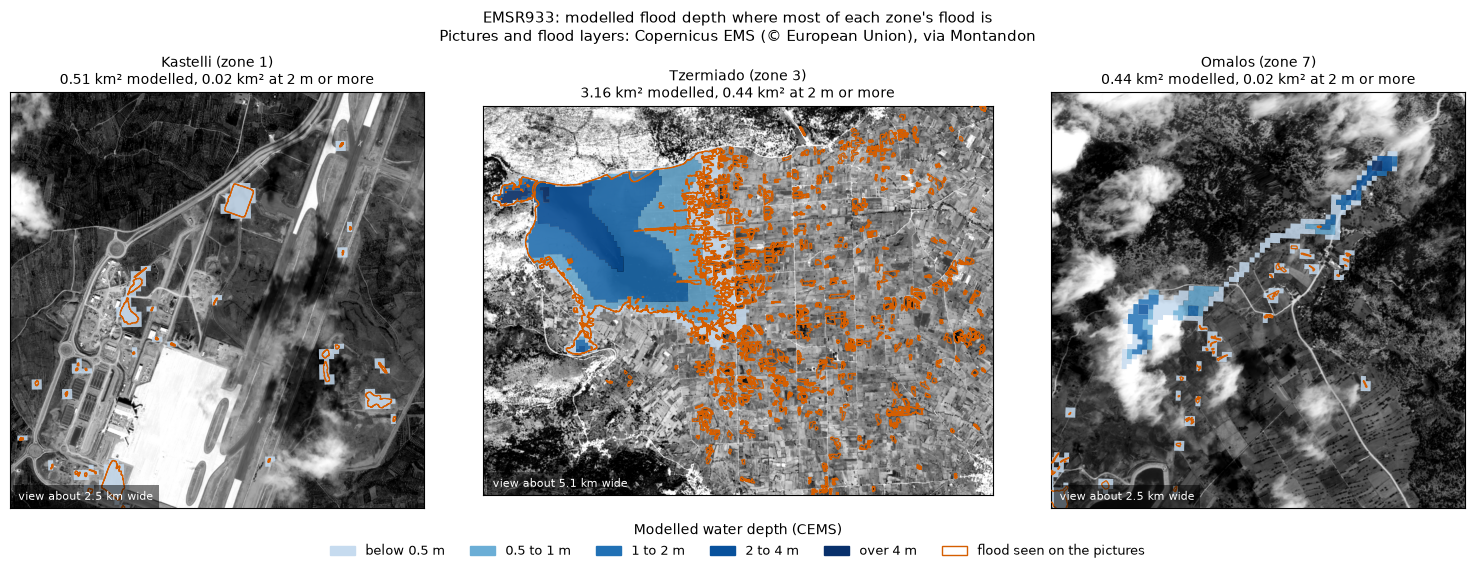

In [24]:
# ---- Appendix: one static depth figure (prints, exports to PDF, shows without internet) ------------
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from rasterio.enums import Resampling

FIGURE_PX = 900          # longest side of each picture read from the COG (a few MB over the network)


def grey_picture(z, bounds_3857):
    """Grey copy of the zone's CEMS picture inside `bounds_3857`, read from a reduced overview of the COG."""
    with open_cog(z.cog_href) as src:
        win = from_bounds(*bounds_3857, transform=src.transform).round_offsets().round_lengths()
        scale = max(win.width, win.height) / FIGURE_PX
        out = (src.count, max(1, int(win.height / scale)), max(1, int(win.width / scale)))
        rgb = src.read(window=win, out_shape=out, resampling=Resampling.average, boundless=True, masked=True)
    grey = rgb[:3].mean(axis=0).filled(np.nan)
    lo, hi = np.nanpercentile(grey, (2, 98))
    return np.clip((grey - lo) / ((hi - lo) or 1), 0, 1)


fig, axes = plt.subplots(1, len(depth_zones), figsize=(5.2 * len(depth_zones), 5.6), constrained_layout=True)
for ax, n in zip(np.atleast_1d(axes), depth_zones):
    z = zones[n]
    best, _, utm_crs = main_flood_area(n)
    w, s, e, nn = gpd.GeoSeries([best], crs=utm_crs).to_crs(3857).total_bounds
    if z.cog_href:
        ax.imshow(grey_picture(z, (w, s, e, nn)), extent=(w, e, s, nn), cmap="gray", vmin=0, vmax=1, zorder=0)
    zone_depth = depth[depth["zone"] == n].to_crs(3857)
    for c in DEPTH_CLASSES:
        part = zone_depth[zone_depth[DEPTH_COL] == c]
        if not part.empty:
            part.plot(ax=ax, color=DEPTH_COLOR[c], alpha=0.85, linewidth=0, zorder=2)
    seen_g[seen_g["zone"] == n].to_crs(3857).boundary.plot(ax=ax, color=SEEN_COLOR, linewidth=0.9, zorder=3)
    ax.set_xlim(w, e)
    ax.set_ylim(s, nn)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    deep = depth_km2.loc[n, [c for c in DEPTH_CLASSES if depth_floor(c) >= 2]].sum()
    ax.set_title(f"{z.name} (zone {n})\n{fmt_km2(depth_km2.loc[n].sum())} km² modelled, {fmt_km2(deep)} km² at 2 m or more",
                 fontsize=10)
    width_km = (best.bounds[2] - best.bounds[0]) / 1000
    ax.text(0.02, 0.02, f"view about {width_km:.1f} km wide", transform=ax.transAxes, fontsize=8,
            color="white", bbox=dict(facecolor="black", alpha=0.5, linewidth=0))

fig.legend(handles=[Patch(color=DEPTH_COLOR[c], label=depth_label(c)) for c in DEPTH_CLASSES]
           + [Patch(facecolor="none", edgecolor=SEEN_COLOR, label="flood seen on the pictures")],
           loc="outside lower center", ncol=len(DEPTH_CLASSES) + 1, frameon=False, fontsize=9,
           title="Modelled water depth (CEMS)")
fig.suptitle(f"{ACTIVATION}: modelled flood depth where most of each zone's flood is\n"
             "Pictures and flood layers: Copernicus EMS (© European Union), via Montandon", fontsize=11)
plt.show()